### Loading the dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_market_calendars as mcal

In [2]:
# Load historical META data
df = pd.read_csv(
    "../data/raw/META_5min.csv",
    parse_dates=["timestamp"]
)

df.head()

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,META,2025-11-03 14:30:00+00:00,656.000,657.6500,652.0000,653.710,1542478.0,63943.0,655.216851
1,META,2025-11-03 14:35:00+00:00,653.710,656.9600,653.5001,653.900,715405.0,28532.0,654.975565
2,META,2025-11-03 14:40:00+00:00,653.845,655.1400,652.0100,653.680,619718.0,22155.0,653.820137
3,META,2025-11-03 14:45:00+00:00,653.680,655.2199,652.2600,654.985,578428.0,20312.0,654.103077
4,META,2025-11-03 14:50:00+00:00,654.940,657.0600,653.7215,655.740,592915.0,19193.0,655.716763


### Understanding the dataset

In [3]:
# Dataset dimension
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nData information:")
df.info()

# Statistical summary
df.describe()

Shape: (19428, 9)

Columns:
['symbol', 'timestamp', 'open', 'high', 'low', 'close', 'volume', 'trade_count', 'vwap']

Data information:
<class 'pandas.DataFrame'>
RangeIndex: 19428 entries, 0 to 19427
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   symbol       19428 non-null  str                
 1   timestamp    19428 non-null  datetime64[us, UTC]
 2   open         19428 non-null  float64            
 3   high         19428 non-null  float64            
 4   low          19428 non-null  float64            
 5   close        19428 non-null  float64            
 6   volume       19428 non-null  float64            
 7   trade_count  19428 non-null  float64            
 8   vwap         19428 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(7), str(1)
memory usage: 1.3 MB


,open,high,low,close,volume,trade_count,vwap
count,19428.000000,19428.000000,19428.000000,19428.000000,1.942800e+04,19428.00000,19428.000000
mean,633.886004,634.740922,633.015543,633.881939,1.828989e+05,5533.03428,633.886845
std,48.413279,48.482082,48.343130,48.415581,2.047359e+05,4826.76150,48.413419
min,521.080000,521.499900,520.260000,521.080000,2.166700e+04,1111.00000,520.959592
25%,600.740000,601.627500,600.000000,600.690000,7.982150e+04,2950.00000,600.834209
50%,631.642300,632.495000,630.585000,631.639950,1.221650e+05,4152.00000,631.573683
75%,663.115625,663.881250,662.332500,663.092525,2.066092e+05,6239.00000,663.078413
max,779.560000,779.819200,777.770000,779.620000,6.327773e+06,116705.00000,778.774097


### Checking missing values and duplicates


In [4]:
print("Missing values:")
display(df.isnull().sum())

print("duplicate timestamps:")
print(df["timestamp"].duplicated().sum())

Missing values:


symbol         0
timestamp      0
open           0
high           0
low            0
close          0
volume         0
trade_count    0
vwap           0
dtype: int64

duplicate timestamps:
0


### Validating OHLC data

In [5]:
invalid_ohlc = df[
    (df["high"] < df["low"]) |
    (df["high"] < df["open"]) |
    (df["high"] < df["close"]) |
    (df["low"] > df["open"]) |
    (df["low"] > df["close"])
]

print("Invalid OHLC rows:", len(invalid_ohlc))

print("Negative volume rows:", (df["volume"]<0).sum())

Invalid OHLC rows: 0
Negative volume rows: 0


### Analyze trading sessions

In [6]:
df["ny_timestamp"] = (
    df["timestamp"].dt.tz_convert("America/New_York")
)

df["trading_date"] = df["ny_timestamp"].dt.date

df["time"] = df["ny_timestamp"].dt.time

df.head()

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap,ny_timestamp,trading_date,time
0,META,2025-11-03 14:30:00+00:00,656.000,657.6500,652.0000,653.710,1542478.0,63943.0,655.216851,2025-11-03 09:30:00-05:00,2025-11-03,09:30:00
1,META,2025-11-03 14:35:00+00:00,653.710,656.9600,653.5001,653.900,715405.0,28532.0,654.975565,2025-11-03 09:35:00-05:00,2025-11-03,09:35:00
2,META,2025-11-03 14:40:00+00:00,653.845,655.1400,652.0100,653.680,619718.0,22155.0,653.820137,2025-11-03 09:40:00-05:00,2025-11-03,09:40:00
3,META,2025-11-03 14:45:00+00:00,653.680,655.2199,652.2600,654.985,578428.0,20312.0,654.103077,2025-11-03 09:45:00-05:00,2025-11-03,09:45:00
4,META,2025-11-03 14:50:00+00:00,654.940,657.0600,653.7215,655.740,592915.0,19193.0,655.716763,2025-11-03 09:50:00-05:00,2025-11-03,09:50:00


In [7]:
daily_counts = df.groupby("trading_date").size()

print("Total candles:", len(df))
print("Trading days:", len(daily_counts))

print("\nDaily candle count:")
print(daily_counts.describe())

print("\nDuplicate timestamps:",
      df["timestamp"].duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())
print("\nMinimum candles:", daily_counts.min())
print("Maximum candles:", daily_counts.max())

daily_counts.describe()

Total candles: 19428
Trading days: 250

Daily candle count:
count    250.000000
mean      77.712000
std        3.213466
min       42.000000
25%       78.000000
50%       78.000000
75%       78.000000
max       78.000000
dtype: float64

Duplicate timestamps: 0

Missing values:
symbol          0
timestamp       0
open            0
high            0
low             0
close           0
volume          0
trade_count     0
vwap            0
ny_timestamp    0
trading_date    0
time            0
dtype: int64

Minimum candles: 42
Maximum candles: 78


count    250.000000
mean      77.712000
std        3.213466
min       42.000000
25%       78.000000
50%       78.000000
75%       78.000000
max       78.000000
dtype: float64

### Visualizing META's closing price

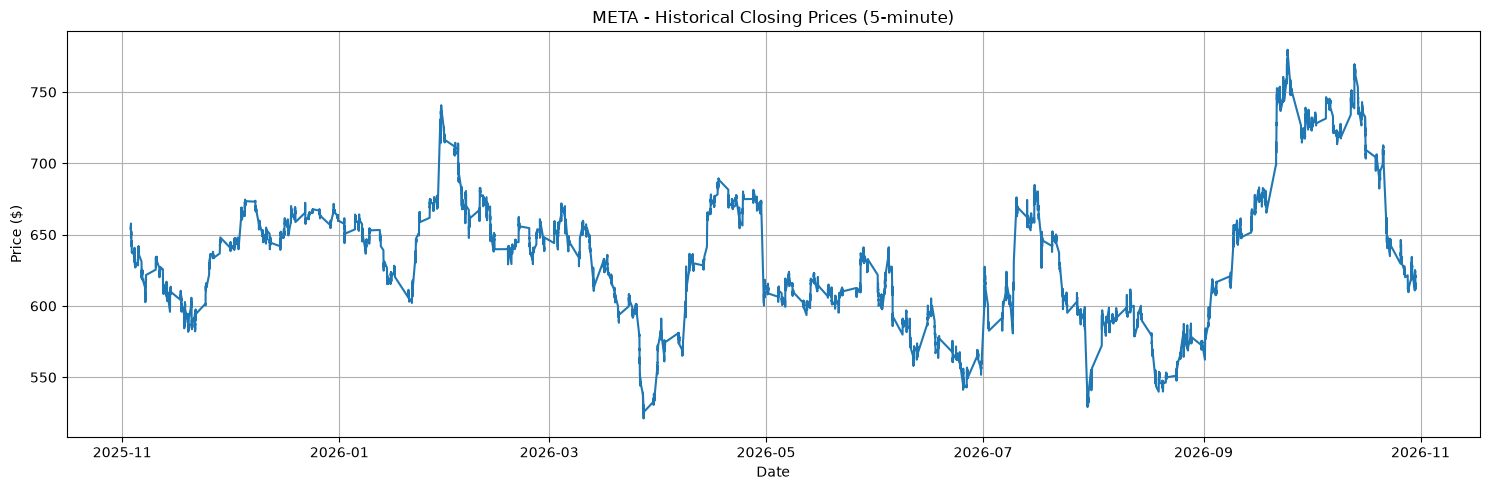

In [8]:
plt.figure(figsize=(15,5))

plt.plot(df["ny_timestamp"], df["close"])

plt.title("META - Historical Closing Prices (5-minute)")
plt.xlabel("Date")
plt.ylabel("Price ($)")

plt.grid(True)
plt.tight_layout()
plt.show()

### Visualizing trading volume

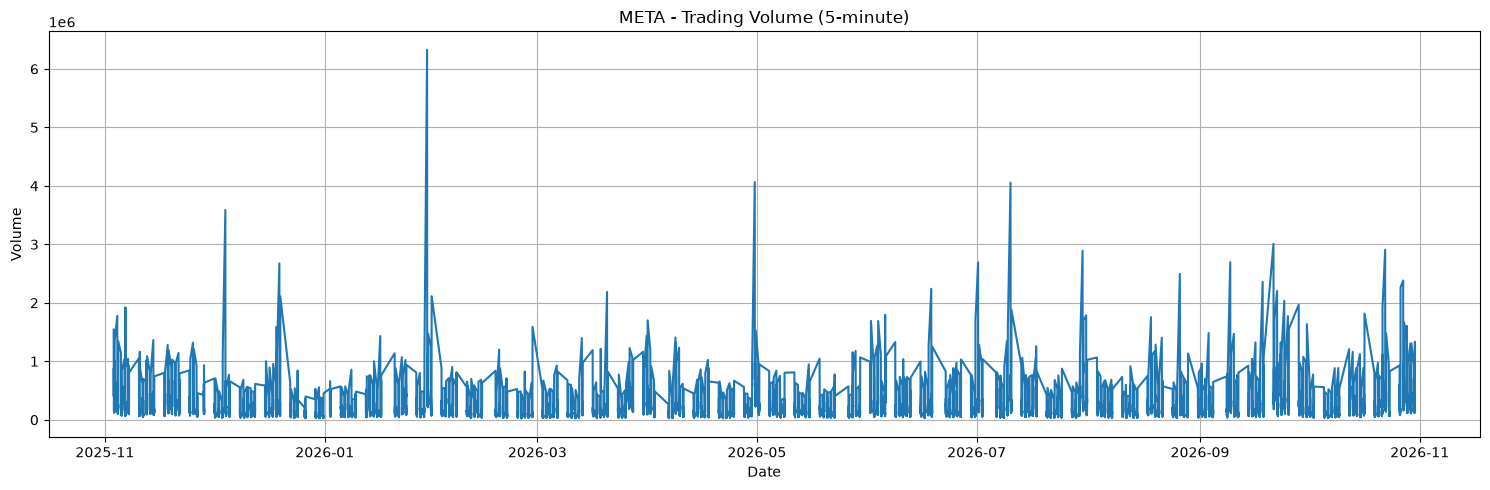

In [9]:
plt.figure(figsize=(15,5))

plt.plot(df["ny_timestamp"], df["volume"])

plt.title("META - Trading Volume (5-minute)")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.grid(True)
plt.tight_layout()
plt.show()

### Investigating missing intervals

In [10]:
df = df.sort_values("timestamp").copy()

df["time_difference"] = (
    df.groupby("trading_date")["timestamp"].diff()
)

gaps = df[
    df["time_difference"] > pd.Timedelta(minutes=5)
]

print("Intervals greater than 5 minutes:", len(gaps))

display(
    gaps[["ny_timestamp", "time_difference"]].head(20)
)

Intervals greater than 5 minutes: 0


,ny_timestamp,time_difference


In [11]:
short_days = daily_counts[daily_counts < 78]

print("Days with fewer than 78 candles:")
display(short_days)

Days with fewer than 78 candles:


trading_date
2025-11-28    42
2025-12-24    42
dtype: int64

Nov 28, 2025 is Day after Thanksgiving <br>
Dec 24, 2025 is Christmas Eve

In [12]:
# Expected vs Actual Candle Validation

EXCHANGE_TIMEZONE = "America/New_York"
EXCHANGE_CALENDAR = "NASDAQ"

# 1. Initialize NASDAQ calendar
nasdaq = mcal.get_calendar(EXCHANGE_CALENDAR)

# 2. Generate official trading schedule
schedule = nasdaq.schedule(
    start_date=df["timestamp"].min().date(),
    end_date=df["timestamp"].max().date()
)

# 3. Generate expected candle timestamps
expected_timestamps = []

for _, row in schedule.iterrows():

    session_times = pd.date_range(
        start=row["market_open"],
        end=row["market_close"],
        freq="5min",
        inclusive="left"
    )

    expected_timestamps.extend(session_times)

expected_timestamps = pd.DatetimeIndex(
    expected_timestamps
)

# 4. Get actual candle timestamps
actual_timestamps = pd.DatetimeIndex(
    df["timestamp"]
)

# 5. Compare expected and actual timestamps
missing = expected_timestamps.difference(
    actual_timestamps
)

unexpected = actual_timestamps.difference(
    expected_timestamps
)

# 6. Display results
print("Expected candles:", len(expected_timestamps))
print("Actual candles:", len(actual_timestamps))
print("Missing candles:", len(missing))
print("Unexpected candles:", len(unexpected))

print("\nMissing timestamps:")
print(missing)

print("\nUnexpected timestamps:")
print(unexpected)

Expected candles: 19428
Actual candles: 19428
Missing candles: 0
Unexpected candles: 0

Missing timestamps:
DatetimeIndex([], dtype='datetime64[us, UTC]', freq=None)

Unexpected timestamps:
DatetimeIndex([], dtype='datetime64[us, UTC]', freq=None)
